**Exercise 1: Basic Usage of SciPy**

**Task**: Import the SciPy library and explore its version.

In [3]:
import scipy
print(scipy.__version__)

1.16.3


**Exercise 2: Descriptive Statistics**

**Task**: Given a sample dataset, calculate the mean, median, variance, and standard deviation using SciPy.

Sample Dataset: data = [12, 15, 13, 12, 18, 20, 22, 21]

In [8]:
import numpy as np
import scipy.stats as stats

In [14]:
sample_data = [12, 15, 13, 12, 18, 20, 22, 21]
avg = stats.tmean(sample_data)
med = np.median(sample_data)
var = stats.tvar(sample_data)
std_dev = stats.tstd(sample_data)

print(f"Mean: {avg}")
print(f"Median: {med}")
print(f"Variance: {var}")
print(f"Standard Deviation: {std_dev}")

Mean: 16.625
Median: 16.5
Variance: 17.125
Standard Deviation: 4.138236339311712


**Exercise 3: Understanding Distributions**

**Task**: Generate a normal distribution using SciPy with a mean of 50 and a standard deviation of 10. Plot this distribution.

Code Example:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [15]:
import matplotlib.pyplot as plt
from scipy.stats import norm

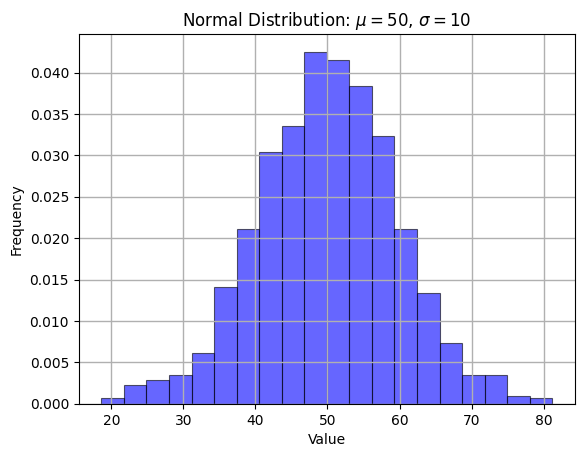

In [39]:
#generate 1000 normally distributed data points:
normal_distr = norm.rvs(loc=50, scale=10, size=1000)

plt.hist(normal_distr, bins=20, density=True, alpha=0.6, color='b',edgecolor='black', linewidth=0.8)
plt.title("Normal Distribution: $\\mu=50$, $\\sigma=10$")
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.grid(True, which = "both",axis='both',linewidth=1)
plt.show()

**Exercise 4: T-Test Application**

**Task**: Perform a T-test on two sets of randomly generated data.
Code Example: data1 = np.random.normal(50, 10, 100)
data2 = np.random.normal(60, 10, 100)

In [41]:
from scipy.stats import ttest_ind

data1 = np.random.normal(50, 10, 100)
data2 = np.random.normal(60, 10, 100)

t_stat, p_val = stats.ttest_ind(data1, data2)
print(f"T-statistic: {t_stat}")
print(f"P-value: {p_val}")

# Look up the critical t values from the T-table
from scipy.stats import t
df = len(data1) + len(data2) - 2
alpha = 0.01

critical_val = t.ppf(1-alpha/2, df)
print(f"Critical Value: {critical_val}")

T-statistic: -8.622954401800595
P-value: 2.092991199233253e-15
Critical Value: 2.6008872779626224


Test 1 at alpha 0.05:

p-value < 0.05.
Also abs(T-Statistic) ~= 4.974 is larger than the critical value of ~1.972 --> the difference in 2 sample means is statistically significant at 95% confidence level.

Test 2 at alpha 0.01:


p-value =2.1E-15< 0.01.
Also abs(T-Statistic) ~= 8.62 is larger than the critical value of ~2.60 --> the difference in 2 sample means is statistically significant at 99% confidence level as well.

H0 can be rejected at 99% confidence level.

**Exercise 5: Linear Regression Analysis**

**Objective**: Apply linear regression to a dataset and interpret the results.

**Task**: Given a dataset of housing prices (house_prices) and their corresponding sizes (house_sizes), use linear regression to predict the price of a house given its size.


*    **Dataset**:
     house_sizes: [50, 70, 80, 100, 120] (in square meters)
     house_prices: [150,000, 200,000, 210,000, 250,000, 280,000] (in currency units)

*    **Questions**:
     What is the slope and intercept of the regression line?
     Predict the price of a house that is 90 square meters.
     Interpret the meaning of the slope in the context of housing prices.

In [42]:
# Data
house_sizes = [50, 70, 80, 100, 120]
house_prices = [150000, 200000, 210000, 250000, 280000]

In [43]:
# Linear regression
slope, intercept, r_value, p_value, std_err = stats.linregress(house_sizes, house_prices)
print(f"Slope is: {slope}")
print(f"Intercept is: {intercept}")
print(f"r_value is: {r_value}")
print(f"p_value is: {p_value}")

Slope is: 1828.7671232876712
Intercept is: 64383.56164383562
r_value is: 0.9941945063380758
p_value is: 0.0005305349938203051


p_value is 0.0005 meaining the slope is statistically singificantly different from 0.

r_value of 0.99 shows a large portion (99%) of variance in house prices is explained by the house size variable.

In [51]:
# Predicting value for a size = 90:

def linear_predict_price(size):
  global slope, intercept
  price = intercept + slope * size
  return price

print(f"expected price for a house of 90 sqm is: {linear_predict_price(90)}")

expected price for a house of 90 sqm is: 228972.60273972602


In context of housing prices, slope illustrates how much the price increases per additional square meter. In our data set and linear model, it increases roughly 1828 currency units per square meter

**Exercise 6: Understanding ANOVA**

**Objective:** Test understanding of ANOVA and its application.

**Task**: Three different fertilizers are applied to three separate groups of plants to test their effectiveness. The growth in centimeters is recorded.

*    **Dataset**:

    fertilizer_1: [5, 6, 7, 6, 5]
    fertilizer_2: [7, 8, 7, 9, 8]
    fertilizer_3: [4, 5, 4, 3, 4]
*    **Questions**:
   Perform an ANOVA test on the given data. What are the F-value and P-value?

   Based on the P-value, do the fertilizers have significantly different effects on plant growth?

   Explain what would happen if the P-value were greater than 0.05.

In [56]:
# Data:

fertilizer_1 = [5, 6, 7, 6, 5]
fertilizer_2 = [7, 8, 7, 9, 8]
fertilizer_3 = [4, 5, 4, 3, 4]

print(f"average growth in cm for fertilizer 1: {np.mean(fertilizer_1)}")
print(f"average growth in cm for fertilizer 2: {np.mean(fertilizer_2)}")
print(f"average growth in cm for fertilizer 3: {np.mean(fertilizer_3)}")

average growth in cm for fertilizer 1: 5.8
average growth in cm for fertilizer 2: 7.8
average growth in cm for fertilizer 3: 4.0


In [55]:

# Performing one-way ANOVA
F_value, p_value = stats.f_oneway(fertilizer_1, fertilizer_2, fertilizer_3)

print(f"F-value is: {F_value}")
print(f"P-value is: {p_value}")

F-value is: 28.52631578947368
P-value is: 2.754267209804844e-05


P-value is ~ 2.75E-5 really low, which means we have significantly different means in the 3 groups.

--> So, it can be concluded that fertilizers have different effects on plant growth.

(If the p-value was greather than 0.05, then we couldn't conclude effects on plant growth at a high confidence level)

**Exercise 7: Probability Distributions (Optional)**

*   Work with a binomial distribution: calculate probabilities for different numbers of successes.

*   Example: Calculating the probability of getting exactly 5 heads in 10 coin flips.



In [58]:
# 10 Coin flips -> N=10 trials, p=0.5 probability of a specific outcome (heads in this case):
N = 10; p=0.5
# defining the binomial distribution parameterized with N,p
binom_dist = stats.binom(N, p)

# Probability of exactly 5 heads means Probabiliy Mass Function value at 5, PMF(5):
print("Probability of exactly 5 heads in 10 trials:", binom_dist.pmf(5))

Probability of exactly 5 heads in 10 trials: 0.24609375000000003


**Exercise 8: Correlation Coefficients (Optional)**

Calculate the Pearson and Spearman correlation coefficients between two variables in a dataset.

Example in code: data = pd.DataFrame({'age': [23, 25, 30, 35, 40], 'income': [35000, 40000, 50000, 60000, 70000]})

In [59]:
import pandas as pd
data = pd.DataFrame({'age': [23, 25, 30, 35, 40], 'income': [35000, 40000, 50000, 60000, 70000]})
data.head()

,age,income
0,23,35000
1,25,40000
2,30,50000
3,35,60000
4,40,70000


In [69]:
correl, pval = stats.pearsonr(data['age'], data['income'])
print(f"Pearson correlation coefficient: {correl}, with p-value of {pval}")

spearman_correl, sp_pval = stats.spearmanr(data['age'], data['income'])
print(f"Spearman correlation coefficient: {spearman_correl}, with p-value of {sp_pval}")

Pearson correlation coefficient: 0.9996907452347201, with p-value of 6.528122732016007e-06
Spearman correlation coefficient: 0.9999999999999999, with p-value of 1.4042654220543672e-24


Both pearson and spearman correlations are very high, almost perfect, and highly significant at a confidence level higher than 99%.